# Single kidney GFR of donor kidneys

Use case provided by Jakob Spogis, Tuebingen

First we set up the notebook so plots appear in-line

In [1]:
%matplotlib inline

Define the locations of source data and results, and load the data:

In [2]:
datafile = r'C:\Users\md1spsx\Documents\Data\dcmri\jakob_spogis\Patients_1_10_27.dmr'
outputdir = r'C:\Users\md1spsx\Documents\Data\dcmri\jakob_spogis\results'

from ntbk_dcmri.utils.data_loaders import load_spogis
all_data = load_spogis(datafile)

Before we proceed to analyse all cases, lets fit a single subject so we can look at the results

In [3]:
from ntbk_dcmri.donor_gfr_validation import fit_single_subj

# Get the first subject
all_subjects = list(all_data.keys())
subj = all_subjects[0]

# Fit the model for the first subject
model, result = fit_single_subj(subj, all_data[subj], outputdir)

   Iteration     Total nfev        Cost      Cost reduction    Step norm     Optimality   
       0              1         6.3154e+02                                    5.95e+03    
       1              2         1.2819e+02      5.03e+02       2.19e-01       9.11e+02    
       2              3         3.4719e+01      9.35e+01       2.68e-01       1.69e+02    
       3              4         2.0821e+01      1.39e+01       2.53e-01       3.61e+02    
       4              5         4.2816e+00      1.65e+01       8.54e-02       7.32e+00    
       5              6         3.6320e+00      6.50e-01       1.98e-01       1.19e+01    
       6              7         3.2566e+00      3.75e-01       9.86e-02       3.48e+01    
       7              8         2.8216e+00      4.35e-01       1.10e-01       1.25e+01    
       8              9         2.3553e+00      4.66e-01       1.89e-01       9.60e+00    
       9             11         2.1412e+00      2.14e-01       7.18e-02       1.11e+00    

All results are saved in the output directory, but we can also look at them interactively to check if all has gone as expected. First, the plot of the model fit against the data will tell us whether the model has converged to a solution:

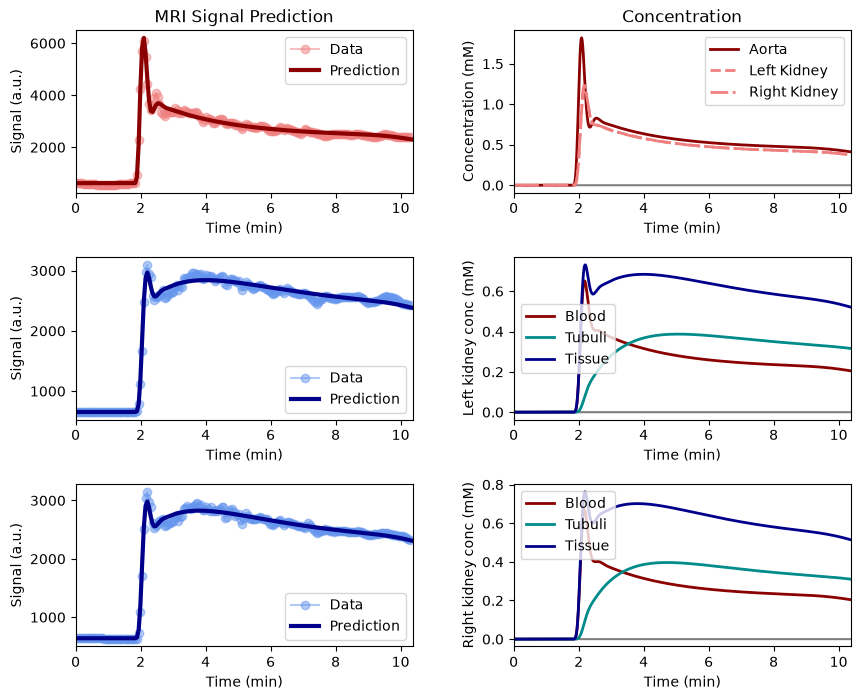

In [4]:
model.plot(all_data[subj], result)

This shows that the model describes the data well, and concentrations are in an expected range. Next we can check that all parameters are well-determined:

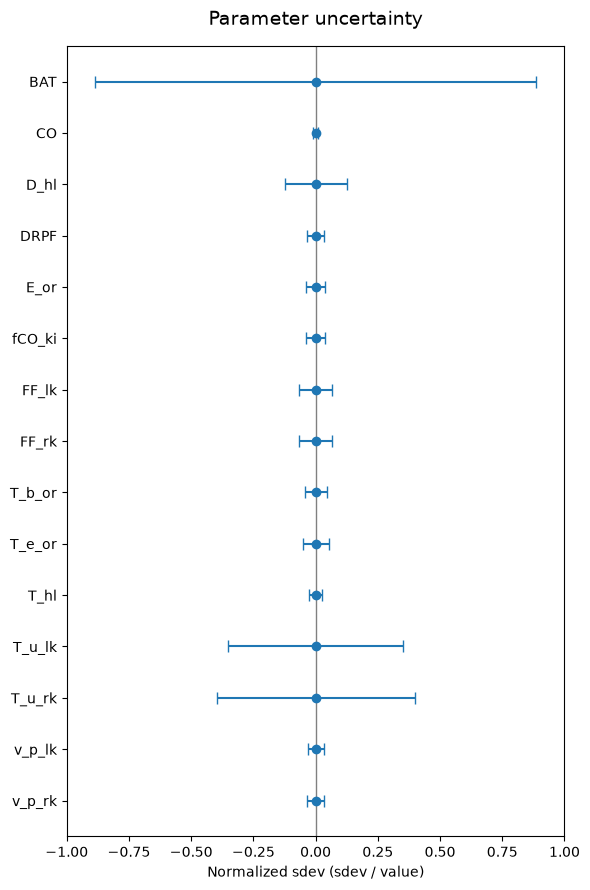

In [5]:
model.plot_pvar(result, xlim=[-1, 1])

The bolus arrival time is typically a fairly uncertain parameter, but also not of interest as a marker of biology. The mean transit times through the tubuluar space are also relatively undetermined with a standard deviation of about half the value. 

They key parameters of interest in this study are all well-determined, ie. the filtration fractions (FF) and the parameters determining the flow to individual kidneys: Cardiac output (CO), differential renal plasma flow (DRPF) and the fraction of the cardiac output to the kidneys (fCO_ki).

Next it is useful to check if any parameters are correlated, as this points to a redundancy in the model:

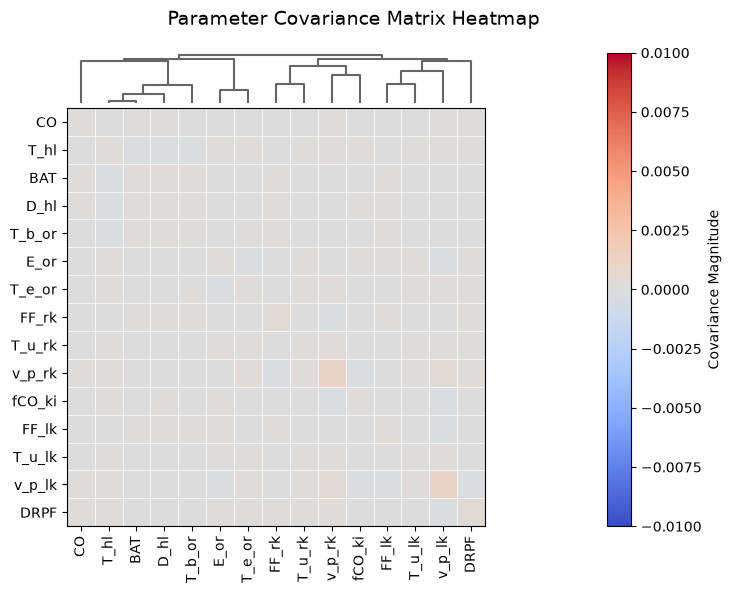

In [6]:
model.plot_pcov(result, vmin=-0.01, vmax=0.01)

As we can see the correlations are very small, which suggests that all parameters play a role. Finally we can check the measured and derived parameters directly: 

In [7]:
model.print(result, digits=3)

+----------------------------------------------------------------------------------------------------------------------------------------+
|                                                               Quantities                                                               |
+--------+--------+------------+--------------------------------------------------------+-----------------+--------------+-------+-------+
| Key    | Value  | Unit       | Name                                                   | Group           | Bounds       | DICOM | OSIPI |
+--------+--------+------------+--------------------------------------------------------+-----------------+--------------+-------+-------+
| BAT    | 107.0  | sec        | bolus arrival time                                     | indicator       | (-30, 30)    |       |       |
+--------+--------+------------+--------------------------------------------------------+-----------------+--------------+-------+-------+
| CO     | 253.0  | mL/sec 

Let's compare the GFR to the measured GFR with nuclear medicine, in more conventional units of mL/min:

In [8]:
print(f"MR GFR (mL/min): {result['pars']['GFR'] * 60:.2f}")
print(f"Nm GFR (mL/min): {all_data[subj]['nmGFR'] * 60:.2f}")

MR GFR (mL/min): 82.94
Nm GFR (mL/min): 109.00


Now lets run all cases:

In [9]:
from ntbk_dcmri.donor_gfr_validation import run

run(datafile, outputdir)

This has now created output folders showing the above images for each case in the dataset. The main endpoint of the study is the correlation between MR-derived and NM-GFR:

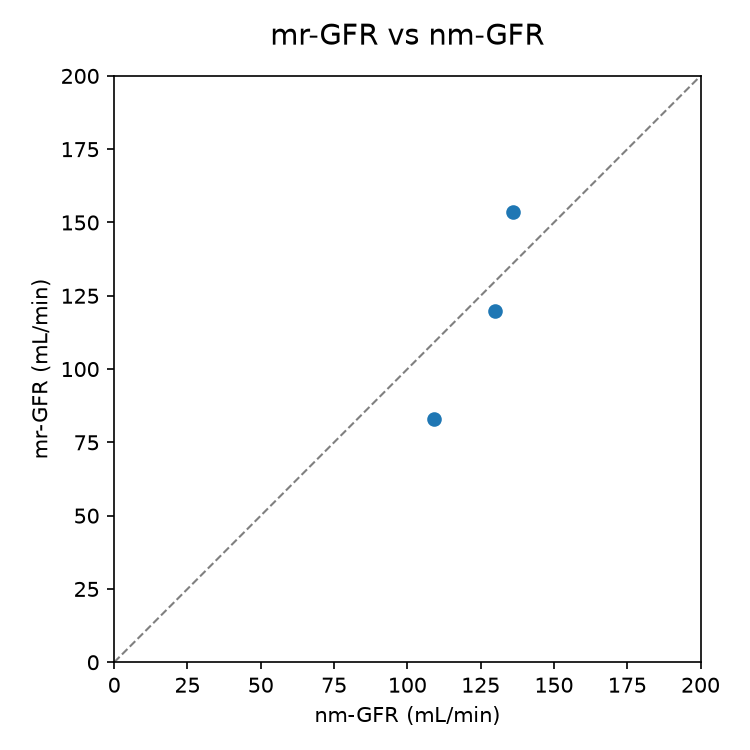

In [10]:
import os
from IPython.display import Image, display

png = os.path.join(outputdir, 'gfr_vs_nmgfr.png')
display(Image(png))